# 3. Order symbols, gauge functions and uniqueness

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 1

Chapter 1 defined an asymptotic expansion in powers of a small parameter. Real
problems need more than powers: logarithms, fractional powers, exponentially small
terms. This chapter introduces the vocabulary for comparing the sizes of functions,
the order symbols, and the idea of a **gauge**, the sequence of functions in which
one expands. It then shows what an asymptotic series does and does not determine:
its coefficients are unique, but the function behind it is not. Three examples
carry the argument: the Lambert $W$ function, whose expansion needs logarithms of
logarithms; the function $e^{-1/x}$, invisible to every power of $x$; and a simple
expansion that holds at each point but not uniformly.

In [1]:
import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 40

## 3.1 Order symbols

As $x \to x_0$ (often $0$ or $\infty$):

* $f = O(g)$, "$f$ is of order $g$", if $|f/g|$ stays bounded;
* $f = o(g)$, "$f$ is much smaller than $g$", written also $f \ll g$, if $f/g \to 0$;
* $f \sim g$, "$f$ is asymptotic to $g$", if $f/g \to 1$.

In applied work $O(g)$ is used a little more loosely, to mean "of the same size
as $g$": the error of a three-term expansion is $O(x^3)$ in that sense. Two common
errors deserve a warning. First, $f \sim g$ says that the *relative* difference
vanishes, not the absolute one: $x^2 + x \sim x^2$ as $x \to \infty$, although the
difference grows without bound. Second, asymptotic equivalence does not survive
exponentiation: $x^2 + x \sim x^2$, but $e^{x^2 + x}/e^{x^2} = e^x \to \infty$.
Inside an exponential, every term that does not vanish must be kept. This is why
Laplace's method (Chapter 6) expands the exponent to second order and the
prefactor only to leading order.

## 3.2 Gauge functions: beyond powers

An asymptotic expansion is written in terms of a **gauge** (or asymptotic
sequence) $\varphi_0, \varphi_1, \varphi_2, \dots$ with $\varphi_{n+1} = o(\varphi_n)$:

$$ f(x) \sim \sum_n a_n \varphi_n(x) \quad\text{means}\quad
   f - \sum_{n<N} a_n\varphi_n = o(\varphi_{N-1}) \text{ for every } N . $$

Powers $x^n$ are the commonest gauge, but problems choose their own. A useful
example is the equation

$$ w\,e^w = z , \qquad z \to \infty , $$

whose solution is the Lambert function $w = W(z)$. It appears whenever an unknown
sits both outside and inside an exponential: in the integrated Michaelis–Menten
rate law of enzyme kinetics, in the current of a diode with series resistance, in
the time for a population to reach a threshold. Taking logarithms,
$w = \ln z - \ln w$. Since $w$ is much smaller than $z$ but grows without bound,
iteration gives $w \approx \ln z - \ln\ln z + \dots$, and carrying the iteration
further (Corless et al. 1996) gives, with $L_1 = \ln z$ and
$L_2 = \ln\ln z$,

$$ W(z) \sim L_1 - L_2 + \frac{L_2}{L_1} + \frac{L_2(L_2 - 2)}{2L_1^2}
   + \frac{L_2(2L_2^2 - 9L_2 + 6)}{6L_1^3} + \dots $$

The gauge here is a double sequence of $L_2^m/L_1^n$, and successive terms are
smaller only by factors of about $L_2/L_1$, which shrink very slowly.

**Checking an expansion in a non-power gauge.** A log-log slope is not useful when
the terms are powers of logarithms. The general test is the definition itself:
the error after $N$ terms divided by the first omitted term must tend to 1.

In [2]:
def lambert_terms(z):
    L1 = np.log(z)
    L2 = np.log(L1)
    return [L1, -L2, L2 / L1, L2 * (L2 - 2) / (2 * L1**2), L2 * (2 * L2**2 - 9 * L2 + 6) / (6 * L1**3)]

zs = np.logspace(1, 80, 60)
W_exact = np.array([float(mp.lambertw(mp.mpf(z))) for z in zs])
terms = lambert_terms(zs)
rel_err, ratio = {}, {}
for N in (1, 2, 3, 4):
    approx = sum(terms[:N])
    rel_err[N] = np.abs(approx - W_exact) / W_exact
    ratio[N] = (W_exact - approx) / terms[N]           # error / first omitted term
for z in (1e2, 1e10, 1e40, 1e80):
    i = np.argmin(np.abs(zs - z))
    print(f"z = {z:.0e}: W = {W_exact[i]:8.4f};  relative error with 1-4 terms: "
          + ", ".join(f"{rel_err[N][i]:.1e}" for N in (1, 2, 3, 4))
          + ";  error / first omitted term: " + ", ".join(f"{ratio[N][i]:.2f}" for N in (1, 2, 3, 4)))

z = 1e+02: W =   1.7455;  relative error with 1-4 terms: 3.2e-01, 1.6e-01, 4.9e-02, 3.7e-03;  error / first omitted term: 0.67, 0.76, 0.93, -4.94
z = 1e+10: W =  17.9156;  relative error with 1-4 terms: 1.6e-01, 8.3e-03, 1.9e-04, 1.1e-05;  error / first omitted term: 0.95, 1.02, 0.95, 1.19
z = 1e+40: W =  87.2444;  relative error with 1-4 terms: 5.1e-02, 5.7e-04, 7.8e-06, 6.8e-08;  error / first omitted term: 0.99, 1.01, 1.01, 0.98
z = 1e+80: W = 179.0193;  relative error with 1-4 terms: 2.9e-02, 1.6e-04, 1.4e-06, 1.0e-08;  error / first omitted term: 0.99, 1.01, 1.01, 1.00


The ratios approach 1 for every truncation, which confirms the expansion term by
term, but they approach it slowly, as $1 + O(L_2/L_1)$. At small $z$ a ratio can be
far from 1, as for four terms at $z = 100$: there the omitted term happens to pass
through zero, and the next one dominates the error. Logarithmic gauges are a
sign of slow convergence: even at $z = 10^{80}$, the two-term approximation
$\ln z - \ln\ln z$ is in error by 0.02 %. Each further term helps, but only by a
factor of about $L_2/L_1$.

## 3.3 Uniqueness, and what it does not mean

Given the gauge, the coefficients of an asymptotic expansion are unique: they are
determined one after another by

$$ a_N = \lim_{x\to 0}\frac{f(x) - \sum_{n<N} a_n\varphi_n(x)}{\varphi_N(x)} . $$

The converse is false: different functions can have the same expansion. The
function $e^{-1/x}$, as $x \to 0^+$, is smaller than every power of $x$,

$$ \frac{e^{-1/x}}{x^n} \to 0 \quad\text{for every } n , $$

so its asymptotic power series is $0 + 0x + 0x^2 + \dots$. It is said to be
**beyond all orders** (or transcendentally small). Adding it to $E(x)$ of
Chapter 1 changes the function but not one coefficient of its series. A power
series therefore cannot determine its function: the information about
exponentially small terms has been lost. Chapter 1 showed that the error of the
optimally truncated series for $E(x)$ is itself of order $e^{-1/x}$, and this is
no coincidence: the series determines its function only up to terms of that size.
Chapter 4 shows how much of the lost information can be recovered.

In [3]:
xg = np.linspace(0.02, 1.0, 400)
for n in (1, 3, 5, 10):
    i = np.argmax(np.exp(-1 / xg) / xg**n)
    print(f"e^(-1/x) / x^{n:<2d}: largest at x = {xg[i]:.3f} (exactly 1/{n} = {1 / n:.3f}),"
          f" where it equals {np.exp(-1 / xg[i]) / xg[i]**n:.3g}")
print(f"at x = 0.02: e^(-1/x) = {np.exp(-50):.1e}, x^10 = {0.02**10:.1e}")

e^(-1/x) / x^1 : largest at x = 1.000 (exactly 1/1 = 1.000), where it equals 0.368
e^(-1/x) / x^3 : largest at x = 0.334 (exactly 1/3 = 0.333), where it equals 1.34
e^(-1/x) / x^5 : largest at x = 0.199 (exactly 1/5 = 0.200), where it equals 21.1
e^(-1/x) / x^10: largest at x = 0.101 (exactly 1/10 = 0.100), where it equals 4.54e+05
at x = 0.02: e^(-1/x) = 1.9e-22, x^10 = 1.0e-17


Each ratio $e^{-1/x}/x^n$ rises to a maximum at $x = 1/n$ and then falls to zero,
so the exponential eventually loses to any fixed power. But the maximum moves
towards $x = 0$ and grows rapidly with $n$: for moderate $x$, "beyond all orders"
does not mean negligible.

## 3.4 Non-uniform expansions

Expansions often depend on a second variable, and an expansion valid at each
point need not be valid everywhere. The simplest example is

$$ f(x;\varepsilon) = \frac{1}{x + \varepsilon} = \frac1x - \frac{\varepsilon}{x^2}
   + \frac{\varepsilon^2}{x^3} - \dots , \qquad \varepsilon \to 0 . $$

For each fixed $x > 0$ this is a perfectly good asymptotic expansion. But the
terms are in the ratio $\varepsilon/x$: the expansion holds only where
$x \gg \varepsilon$, and fails in a thin region of width $\varepsilon$ near the
origin, where the "small" correction is as large as the leading term. Such
expansions are **non-uniform**. The region of failure is where a different
description is needed, with $x$ rescaled as $x = \varepsilon X$, and it is the
prototype of the boundary layers of differential equations (see the companion
book on perturbation methods).

In [4]:
xu = np.logspace(-5, 0, 300)
nonuni = {}
for eps in (1e-2, 1e-3):
    exact = 1 / (xu + eps)
    nonuni[eps] = {N: np.abs(sum((-eps) ** k / xu ** (k + 1) for k in range(N)) - exact) / exact for N in (1, 2, 3)}
    i = np.argmin(np.abs(xu - 10 * eps))
    j = np.argmin(np.abs(xu - eps))
    print(f"eps = {eps:g}: relative error of 2 terms at x = 10 eps: {nonuni[eps][2][i]:.3f};"
          f"  at x = eps: {nonuni[eps][2][j]:.2f}")

eps = 0.01: relative error of 2 terms at x = 10 eps: 0.010;  at x = eps: 1.03
eps = 0.001: relative error of 2 terms at x = 10 eps: 0.010;  at x = eps: 0.97


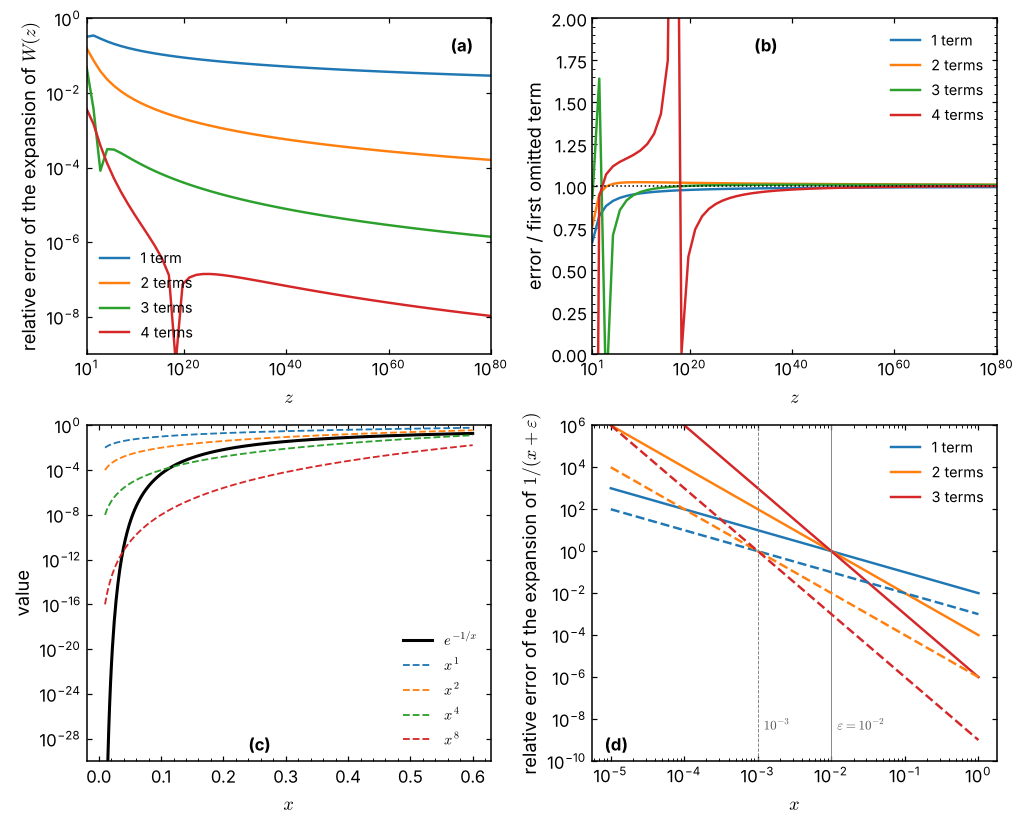

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.loglog(zs, rel_err[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel("$z$"); ax.set_ylabel(r"relative error of the expansion of $W(z)$")
ax.set_xlim(10, 1e80); ax.set_xticks([1e1, 1e20, 1e40, 1e60, 1e80]); ax.set_ylim(1e-9, 1)
ax.legend(loc="lower left"); am.panel_label(ax, "(a)", x=0.9)

ax = axes[0, 1]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.semilogx(zs, ratio[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.axhline(1, color="k", ls=":", lw=1)
ax.set_xlabel("$z$"); ax.set_ylabel("error / first omitted term")
ax.set_xlim(10, 1e80); ax.set_xticks([1e1, 1e20, 1e40, 1e60, 1e80]); ax.set_ylim(0, 2)
ax.legend(loc="upper right"); am.panel_label(ax, "(b)", x=0.4)

ax = axes[1, 0]
xe = np.linspace(0.01, 0.6, 400)
ax.semilogy(xe, np.exp(-1 / xe), "k", lw=2, label=r"$e^{-1/x}$")
for n, c in zip((1, 2, 4, 8), ("C0", "C1", "C2", "C3")):
    ax.semilogy(xe, xe**n, "--", color=c, lw=1.2, label=f"$x^{n}$")
ax.set_xlabel("$x$"); ax.set_ylabel("value")
ax.set_ylim(1e-30, 1); ax.legend(loc="lower right"); am.panel_label(ax, "(c)", x=0.4, y=0.08)

ax = axes[1, 1]
for eps, ls in ((1e-2, "-"), (1e-3, "--")):
    for N, c in zip((1, 2, 3), ("C0", "C1", "C3")):
        ax.loglog(xu, nonuni[eps][N], ls, color=c, label=(f"{N} term" + ("s" if N > 1 else "")) if eps == 1e-2 else None)
    ax.axvline(eps, color="0.5", lw=0.6, ls=ls)
ax.text(1.2e-2, 3e-9, r"$\varepsilon = 10^{-2}$", fontsize=8.5, color="0.35")
ax.text(1.2e-3, 3e-9, r"$10^{-3}$", fontsize=8.5, color="0.35")
ax.set_xlabel("$x$"); ax.set_ylabel(r"relative error of the expansion of $1/(x + \varepsilon)$")
ax.set_ylim(1e-10, 1e6); ax.legend(loc="upper right"); am.panel_label(ax, "(d)", y=0.08)
plt.show()

**(a)** Relative error of the expansion of the Lambert function with one to four
terms. **(b)** The same errors divided by the first omitted term, which tend
(slowly) to 1. **(c)** The function $e^{-1/x}$ against powers of $x$: it is
eventually smaller than each of them. **(d)** Relative error of the expansion of
$1/(x + \varepsilon)$ in powers of $\varepsilon$ for $\varepsilon = 10^{-2}$ (solid)
and $10^{-3}$ (dashed): each expansion fails for $x \lesssim \varepsilon$ (vertical
lines).

## Summary

* $O$, $o$ and $\sim$ compare sizes; $f \sim g$ is a statement about the relative
  difference, and it does not survive exponentiation.
* An expansion is made in a gauge chosen by the problem: powers, logarithms,
  fractional powers. Logarithmic gauges converge slowly.
* In any gauge, the test of an expansion is that the error divided by the first
  omitted term tends to 1.
* The coefficients of an expansion are unique; the function is not. Terms beyond
  all orders, such as $e^{-1/x}$, are invisible to a power series.
* An expansion can hold at each point but fail in a region; such non-uniformities
  point to boundary layers.

## Suggested references

* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* R. M. Corless, G. H. Gonnet, D. E. G. Hare, D. J. Jeffrey and D. E. Knuth, "On
  the Lambert W function", *Adv. Comput. Math.* **5**, 329 (1996).
* N. G. de Bruijn, *Asymptotic Methods in Analysis*, 3rd ed. (North-Holland,
  1970; Dover, 1981).
* E. J. Hinch, *Perturbation Methods* (Cambridge University Press, 1991).
* M. H. Holmes, *Introduction to Perturbation Methods*, 2nd ed. (Springer, 2013).

## Exercises

1. Show that $x + \ln x \sim x$ as $x \to \infty$ but that $e^{x + \ln x}$ is not
   asymptotic to $e^{x}$. Under what condition on $f - g$ does $f \sim g$ imply
   $e^f \sim e^g$?
2. Derive the first three terms of the expansion of $W(z)$ by iterating
   $w = \ln z - \ln w$.
3. Find the large-$z$ expansion of the solution of $w \ln w = z$ to three terms,
   and check it by the ratio test of Section 3.2.
4. Expand $\sqrt{x + \varepsilon}$ for small $\varepsilon$ at fixed $x$. Where does
   the expansion fail, and what is the appropriate inner variable?

---

**Previous:** [2. Scaling: finding the small parameter](02_scaling_and_small_parameters.ipynb) &nbsp;·&nbsp; **Next:** [4. Divergent series in practice](04_divergent_series_in_practice.ipynb)